In [6]:
import os
from google.colab import files


files.upload()
os.makedirs("/root/.kaggle", exist_ok=True)
os.rename("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)


!pip install -q kaggle
!kaggle datasets list | head



Saving kaggle.json to kaggle.json
ref                                                  title                                           size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  ----------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
ahmeduzaki/wind-and-solar-energy-production-dataset  Wind & Solar Energy Production Dataset        395372  2026-01-02 21:06:22.780000              0         30  1.0              
neurocipher/heartdisease                             Heart Disease                                   3491  2025-12-11 15:29:14.327000           2114        189  1.0              
kundanbedmutha/exam-score-prediction-dataset         Exam Score Prediction Dataset                 325454  2025-11-28 07:29:01.047000           5863        238  1.0              
ishank2005/salary-csv                                Salary.csv        

In [7]:

!mkdir -p data
!kaggle competitions download -c medicalnotes-2019 -p data
!unzip -q data/medicalnotes-2019.zip -d data
!ls data




medicalnotes-2019.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/data.zip? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data_split.zip? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/sampleResults.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/trainLabels.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
data		data.zip	       notes		  trainLabels.csv
data_split.zip	medicalnotes-2019.zip  sampleResults.csv


In [8]:
!unzip -q data/data.zip -d data
!ls data | head

replace data/data/1001.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1002.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1003.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1004.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1005.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1006.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1007.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/data/1008.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
data
data_split.zip
data.zip
medicalnotes-2019.zip
notes
sampleResults.csv
trainLabels.csv


In [9]:
import os, re, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score


In [10]:
import pandas as pd
from pathlib import Path

# Base data directory
DATA_DIR = Path("data")

# Notes are inside data/notes/
NOTES_DIR = DATA_DIR / "notes/data"


In [11]:
# Load labels
labels_df = pd.read_csv(DATA_DIR / "trainLabels.csv")
labels_df.columns = ["id", "label"]

def load_note(note_id):
    with open(NOTES_DIR / f"{note_id}", "r", encoding="utf-8", errors="ignore") as f:
        return f.read()

labels_df["text"] = labels_df["id"].apply(load_note)

labels_df.head()



,id,label,text
0,1002.txt,Orthopedic,\n\n\n\n\n<B>PREOPERATIVE DIAGNOSIS: </B> Gang...
1,1003.txt,Orthopedic,\n\n\n\n\n<B>PREOPERATIVE DIAGNOSIS: </B> Cerv...
2,1004.txt,Radiology,\n\n\n\n\n<B>EXAM:</B>MRI LEFT SHOULDER\n\n<B>...
3,1005.txt,Orthopedic,\n\n\n\n\n<B>HISTORY OF PRESENT ILLNESS: </B> ...
4,1006.txt,Orthopedic,\n\n\n\n\n<B>CHIEF COMPLAINT:</B> Decreased a...


In [12]:
print("Number of samples:", len(labels_df))
print("Columns:", labels_df.columns.tolist())
print("Missing texts:", labels_df["text"].isna().sum())
print("Unique classes:", labels_df["label"].nunique())
labels_df["label"].value_counts().head(10)


Number of samples: 825
Columns: ['id', 'label', 'text']
Missing texts: 0
Unique classes: 5


,count
label,
Orthopedic,223
Radiology,188
Gastroenterology,157
Neurology,142
Urology,115


,count
label,
Orthopedic,223
Radiology,188
Gastroenterology,157
Neurology,142
Urology,115


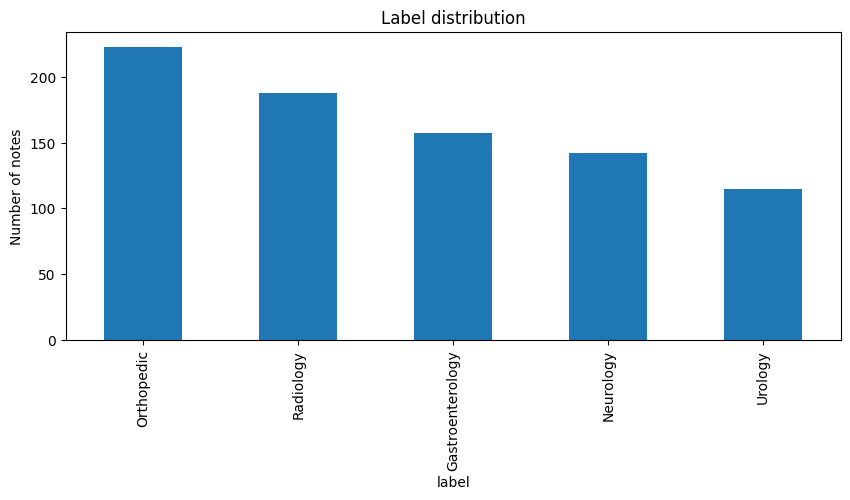

In [13]:
import matplotlib.pyplot as plt

label_counts = labels_df["label"].value_counts()
display(label_counts)

plt.figure(figsize=(10,4))
label_counts.plot(kind="bar")
plt.title("Label distribution")
plt.ylabel("Number of notes")
plt.xticks(rotation=90)
plt.show()


,n_words
count,825.000000
mean,463.974545
std,368.472698
min,0.000000
25%,222.000000
50%,385.000000
75%,595.000000
max,4683.000000


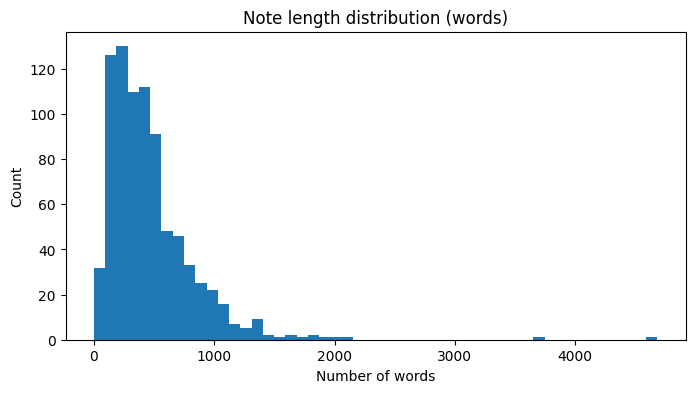

In [14]:
labels_df["n_words"] = labels_df["text"].apply(lambda x: len(str(x).split()))

display(labels_df["n_words"].describe())

plt.figure(figsize=(8,4))
plt.hist(labels_df["n_words"], bins=50)
plt.title("Note length distribution (words)")
plt.xlabel("Number of words")
plt.ylabel("Count")
plt.show()


In [15]:
for lab in labels_df["label"].unique()[:3]:
    ex = labels_df[labels_df["label"] == lab].iloc[0]["text"]
    print("\n------------------")
    print("Label:", lab)
    print(ex[:700])



------------------
Label: Orthopedic





<B>PREOPERATIVE DIAGNOSIS: </B> Ganglion of the left wrist.

<B>POSTOPERATIVE DIAGNOSIS: </B> Ganglion of the left wrist.

<B>OPERATION: </B> Excision of ganglion.

<B>ANESTHESIA: </B> General.

<B>ESTIMATED BLOOD LOSS: </B> Less than 5 mL.

<B>OPERATION: </B> After a successful anesthetic, the patient was positioned on the operating table.  A tourniquet applied to the upper arm.  The extremity was prepped in a usual manner for a surgical procedure and draped off.  The superficial vessels were exsanguinated with an elastic wrap and the tourniquet was then inflated to the usual arm pressure.  A curved incision was made over the presenting ganglion over the dorsal aspect of the wrist.  By

------------------
Label: Radiology





<B>EXAM:</B>MRI LEFT SHOULDER

<B>CLINICAL:</B>This is a 69-year-old male with pain in the shoulder. Evaluate for rotator cuff tear.

<B>FINDINGS:</B>

Examination was performed on 9/1/05.

There is marked supraspinatus

In [16]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def clean_text(text):
    text = str(text)

    # remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # lowercase
    text = text.lower()

    # remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # remove stopwords
    words = text.split()
    words = [w for w in words if w not in stop_words]

    # stemming
    words = [stemmer.stem(w) for w in words]

    return " ".join(words)

labels_df["text_clean"] = labels_df["text"].apply(clean_text)

labels_df[["label", "text_clean"]].head()



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,label,text_clean
0,Orthopedic,preoper diagnosis: ganglion left wrist. postop...
1,Orthopedic,"preoper diagnosis: cervic myelopathy, c3-4, se..."
2,Radiology,exam: mri left shoulder clinical: 69-year-old ...
3,Orthopedic,histori present illness: patient 57-year-old f...
4,Orthopedic,chief complaint: decreas abil perform daili li...


In [17]:
from sklearn.model_selection import train_test_split

X = labels_df["text_clean"]
y = labels_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))


Train size: 660
Test size: 165


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

tfidf_svm = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_df=0.9)),
    ("svm", LinearSVC())
])

tfidf_svm.fit(X_train, y_train)
y_pred = tfidf_svm.predict(X_test)

print("TF-IDF + SVM Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


TF-IDF + SVM Accuracy: 0.7151515151515152
                  precision    recall  f1-score   support

Gastroenterology       0.81      0.94      0.87        31
       Neurology       0.45      0.36      0.40        28
      Orthopedic       0.85      0.89      0.87        45
       Radiology       0.53      0.53      0.53        38
         Urology       0.86      0.83      0.84        23

        accuracy                           0.72       165
       macro avg       0.70      0.71      0.70       165
    weighted avg       0.70      0.72      0.71       165



<Figure size 1000x1000 with 0 Axes>

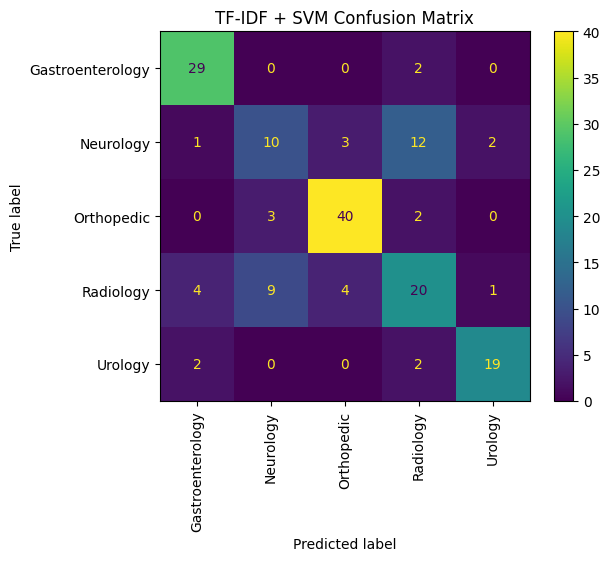

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(10,10))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90)
plt.title("TF-IDF + SVM Confusion Matrix")
plt.show()


BERT FINE TUNE

In [31]:
!pip install -q transformers datasets torch accelerate
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

from datasets import Dataset
from transformers import (
    BertTokenizerFast,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

In [32]:
# Encode labels
labels_df["label_id"] = labels_df["label"].astype("category").cat.codes
label_names = labels_df["label"].astype("category").cat.categories.tolist()

# Train / test split
train_df, test_df = train_test_split(
    labels_df,
    test_size=0.2,
    random_state=42,
    stratify=labels_df["label_id"]
)

# Convert to HuggingFace Dataset
train_ds = Dataset.from_pandas(train_df[["text_clean", "label_id"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label_id"]])

In [33]:
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(
        batch["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_ds = train_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label_id", "labels")
test_ds  = test_ds.rename_column("label_id", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])



Map:   0%|          | 0/660 [00:00<?, ? examples/s]

Map:   0%|          | 0/165 [00:00<?, ? examples/s]

In [34]:
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(label_names)
)



Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [35]:
training_args = TrainingArguments(
    output_dir="./bert_results",
    save_strategy="no",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    learning_rate=5e-5,
    weight_decay=0.5,
    logging_steps=100,
    report_to="none"
)


In [36]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    tokenizer=tokenizer
)

trainer.train()


/tmp/ipython-input-1030325935.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss


TrainOutput(global_step=83, training_loss=1.3169829586902297, metrics={'train_runtime': 1247.0595, 'train_samples_per_second': 0.529, 'train_steps_per_second': 0.067, 'total_flos': 43414493506560.0, 'train_loss': 1.3169829586902297, 'epoch': 1.0})

In [38]:
preds = trainer.predict(test_ds)
y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print("BERT Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=label_names))


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


BERT Accuracy: 0.6121212121212121
                  precision    recall  f1-score   support

Gastroenterology       0.61      0.87      0.72        31
       Neurology       1.00      0.11      0.19        28
      Orthopedic       0.69      0.91      0.79        45
       Radiology       0.50      0.68      0.58        38
         Urology       0.57      0.17      0.27        23

        accuracy                           0.61       165
       macro avg       0.68      0.55      0.51       165
    weighted avg       0.67      0.61      0.55       165

